# MNE-Python intro (10 minutes)

Run each cell with `Shift+Enter`. Close a plot window before moving to the next cell if it's blocking.

## 1. Load a real sample MEG/EEG recording
First run downloads the dataset to `~/mne_data/` (a few hundred MB, one-time).

In [1]:
import mne

sample_dir = mne.datasets.sample.data_path()
raw_path = sample_dir / "MEG" / "sample" / "sample_audvis_raw.fif"
raw = mne.io.read_raw_fif(raw_path, preload=True)
print(raw.info)

Opening raw data file /Users/marinad/mne_data/MNE-sample-data/MEG/sample/sample_audvis_raw.fif...
    Read a total of 3 projection items:
        PCA-v1 (1 x 102)  idle
        PCA-v2 (1 x 102)  idle
        PCA-v3 (1 x 102)  idle
    Range : 25800 ... 192599 =     42.956 ...   320.670 secs
Ready.
Reading 0 ... 166799  =      0.000 ...   277.714 secs...


/Users/marinad/Desktop/projects/mne-explore/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<Info | 21 non-empty values
 acq_pars: ACQch001 110113 ACQch002 110112 ACQch003 110111 ACQch004 110122 ...
 bads: 2 items (MEG 2443, EEG 053)
 ch_names: MEG 0113, MEG 0112, MEG 0111, MEG 0122, MEG 0123, MEG 0121, MEG ...
 chs: 204 Gradiometers, 102 Magnetometers, 9 Stimulus, 60 EEG, 1 EOG
 custom_ref_applied: False
 description: acquisition (megacq) VectorView system at NMR-MGH
 dev_head_t: MEG device -> head transform
 dig: 146 items (3 Cardinal, 4 HPI, 61 EEG, 78 Extra)
 events: 1 item (list)
 experimenter: MEG
 file_id: 4 items (dict)
 highpass: 0.1 Hz
 hpi_meas: 1 item (list)
 hpi_results: 1 item (list)
 lowpass: 172.2 Hz
 meas_date: 2002-12-03 19:01:10 UTC
 meas_id: 4 items (dict)
 nchan: 376
 proj_id: 1
 proj_name: test
 projs: PCA-v1: off, PCA-v2: off, PCA-v3: off
 sfreq: 600.6 Hz
>


## 2. Look at the raw signal

Using matplotlib as 2D backend.
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


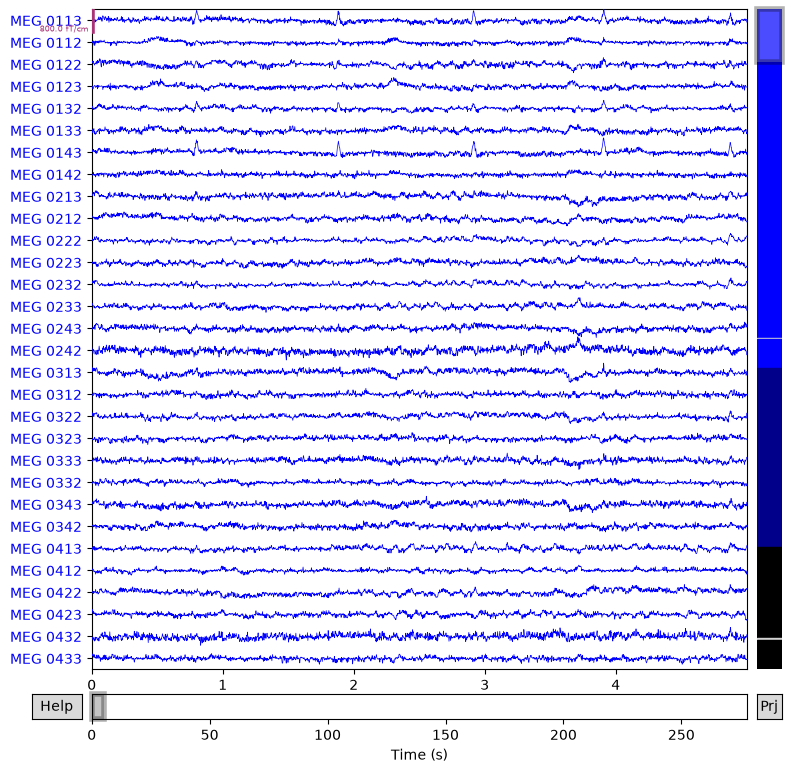

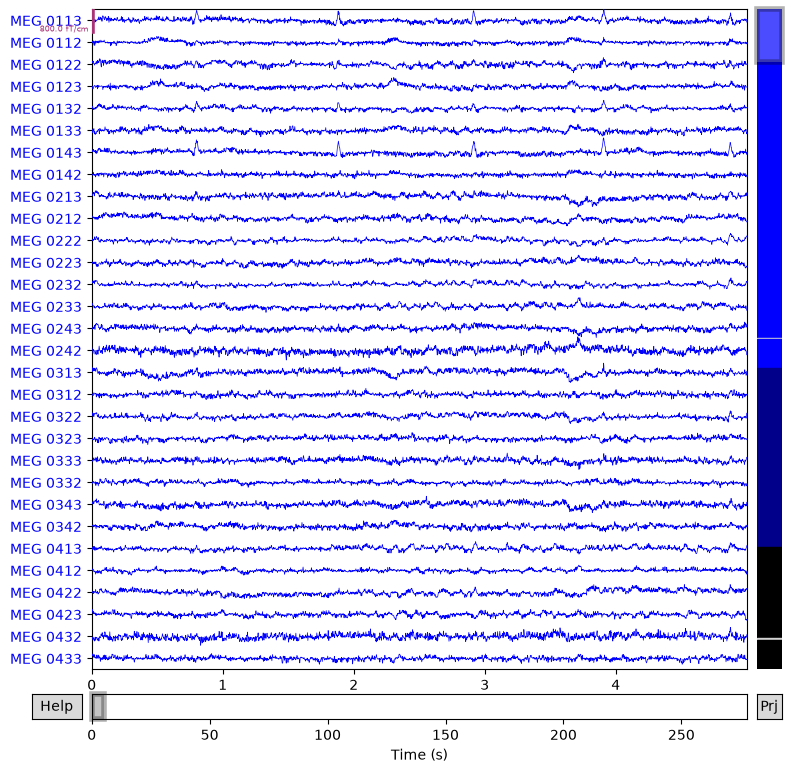

In [2]:
raw.plot(duration=5, n_channels=30)

## 3. Filter out slow drift and high-frequency noise

In [3]:
raw.filter(l_freq=1.0, h_freq=40.0)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 1983 samples (3.302 s)



<Raw | sample_audvis_raw.fif, 376 x 166800 (277.7 s), ~481.7 MiB, data loaded>

## 4. Find the stimulus events embedded in the recording

In [4]:
events = mne.find_events(raw, stim_channel="STI 014")
print(events[:5])

Finding events on: STI 014
320 events found on stim channel STI 014
Event IDs: [ 1  2  3  4  5 32]
[[27977     0     2]
 [28345     0     3]
 [28771     0     1]
 [29219     0     4]
 [29652     0     2]]


## 5. Cut the continuous recording into trials around each event

Not setting metadata
289 matching events found
Setting baseline interval to [-0.19979521315838786, 0.0] s
Applying baseline correction (mode: mean)
Created an SSP operator (subspace dimension = 3)
3 projection items activated
Using data from preloaded Raw for 289 events and 421 original time points ...
0 bad epochs dropped
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


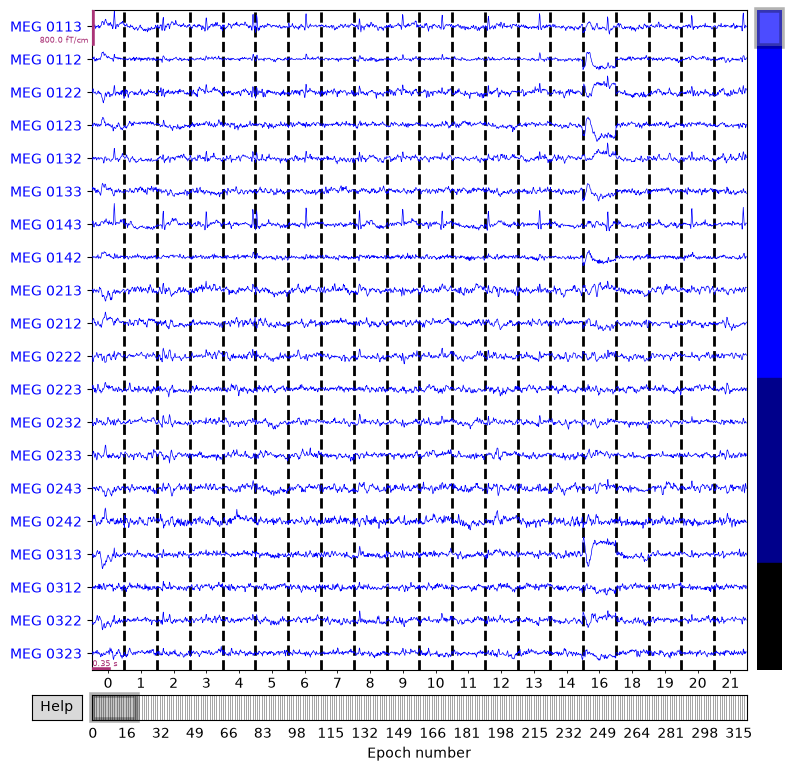

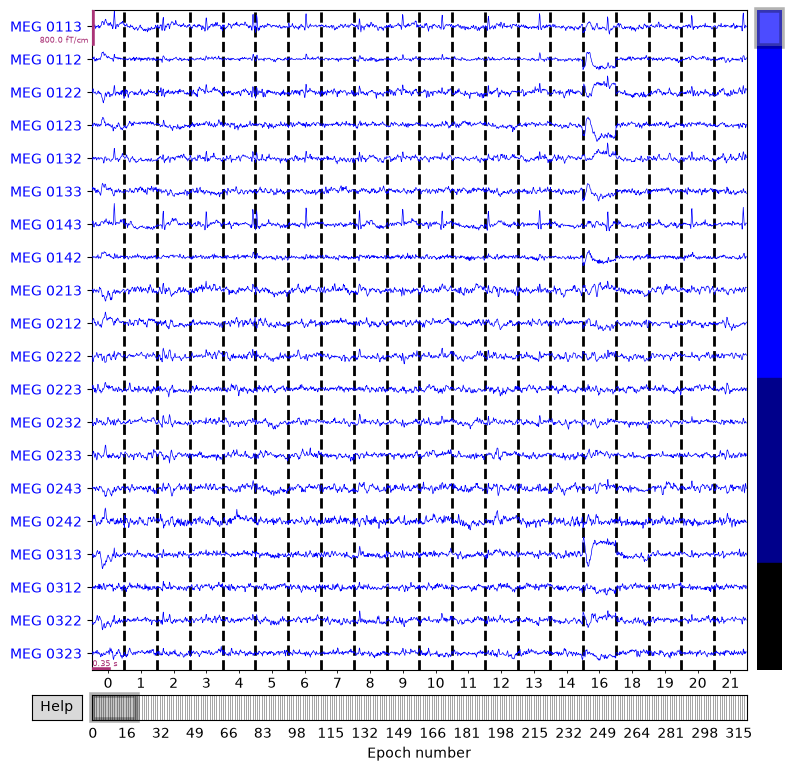

In [5]:
event_id = {"auditory/left": 1, "auditory/right": 2, "visual/left": 3, "visual/right": 4}
epochs = mne.Epochs(raw, events, event_id=event_id, tmin=-0.2, tmax=0.5, preload=True)
epochs.plot()

## 6. Average the trials to get the brain's typical response (ERP/ERF)

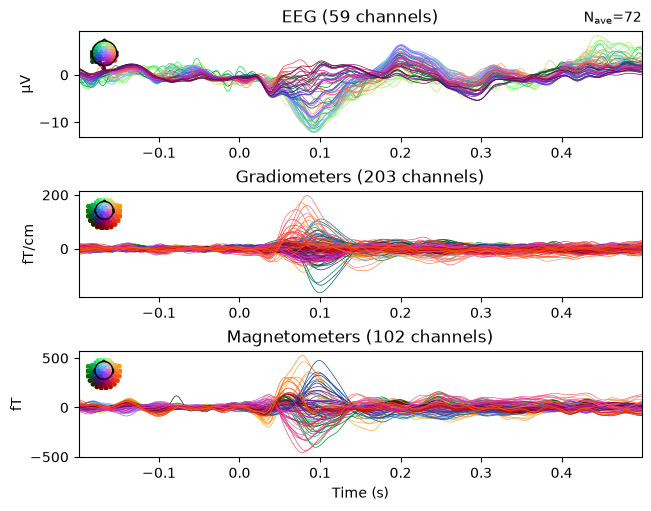

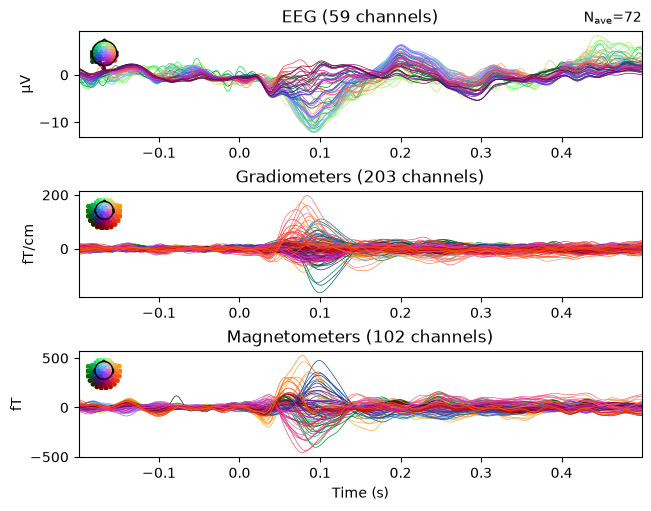

In [6]:
evoked = epochs["auditory/left"].average()
evoked.plot()

## 7. Visualize the response as a scalp map at a chosen time

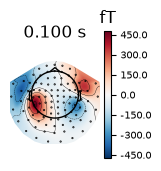

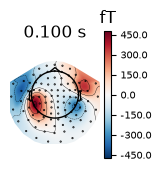

In [7]:
evoked.plot_topomap(times=0.1)